# D1ECD – Estatística para Ciência de Dados
## Atividade Avaliativa 02 – Teste ANOVA

**Nome:** Rodrigo Gimenes Rodrigues  
**Matrícula:** CP3071782  
**Curso:** Especialização em Ciência de Dados  
**Período/Ano:** 2026/2  
**Campus:** Campinas  
**Turno:** EAD  
**Professor:** Kakimoto


## Conjunto de dados

Tempo de permanência no site, em minutos. São 10 usuários em cada algoritmo (A, B, C e D), amostras independentes, no mesmo período.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

dados = {
   'Algoritmo_A': [18.2, 20.1, 17.5, 19.8, 21.0, 18.9, 17.8, 20.5, 19.1, 18.6],
   'Algoritmo_B': [22.5, 24.1, 23.0, 21.8, 25.2, 23.9, 22.1, 24.5, 23.7, 24.0],
   'Algoritmo_C': [19.0, 18.5, 19.8, 20.2, 17.9, 19.1, 18.8, 20.0, 19.3, 18.7],
   'Algoritmo_D': [25.0, 27.3, 26.1, 24.8, 28.0, 26.5, 25.9, 27.0, 26.2, 25.5]
}

df = pd.DataFrame(dados)
df

,Algoritmo_A,Algoritmo_B,Algoritmo_C,Algoritmo_D
0,18.2,22.5,19.0,25.0
1,20.1,24.1,18.5,27.3
2,17.5,23.0,19.8,26.1
3,19.8,21.8,20.2,24.8
4,21.0,25.2,17.9,28.0
5,18.9,23.9,19.1,26.5
6,17.8,22.1,18.8,25.9
7,20.5,24.5,20.0,27.0
8,19.1,23.7,19.3,26.2
9,18.6,24.0,18.7,25.5


## Parte 1 – Hipóteses e análise exploratória

H0: o tempo médio de permanência é o mesmo nos quatro algoritmos.

μA = μB = μC = μD

H1: pelo menos um algoritmo tem média diferente dos demais.


In [2]:
print('Média')
print(df.mean().round(2))
print()
print('Desvio padrão')
print(df.std(ddof=1).round(2))
print()
print('Mediana')
print(df.median().round(2))

Média
Algoritmo_A    19.15
Algoritmo_B    23.48
Algoritmo_C    19.13
Algoritmo_D    26.23
dtype: float64

Desvio padrão
Algoritmo_A    1.17
Algoritmo_B    1.10
Algoritmo_C    0.71
Algoritmo_D    1.01
dtype: float64

Mediana
Algoritmo_A    19.00
Algoritmo_B    23.80
Algoritmo_C    19.05
Algoritmo_D    26.15
dtype: float64


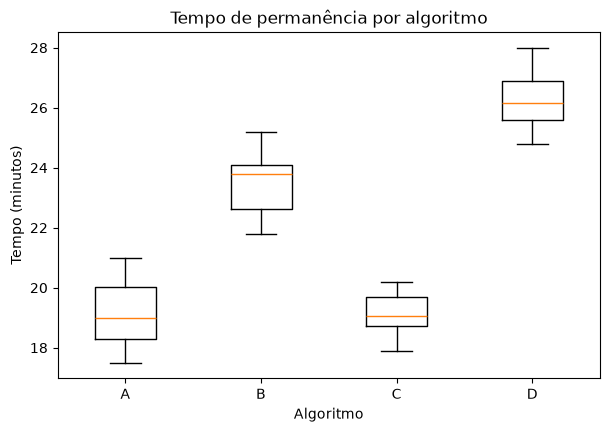

In [3]:
plt.figure(figsize=(7, 4.5))
plt.boxplot(
    [df['Algoritmo_A'], df['Algoritmo_B'], df['Algoritmo_C'], df['Algoritmo_D']],
    tick_labels=['A', 'B', 'C', 'D']
)
plt.title('Tempo de permanência por algoritmo')
plt.xlabel('Algoritmo')
plt.ylabel('Tempo (minutos)')
plt.show()

### Comentário – Parte 1

Rodando o código, as médias foram 19,15 (A), 23,48 (B), 19,13 (C) e 26,23 (D). A e C praticamente empataram. O B ficou cerca de 4,3 minutos acima deles, e o D uns 7 minutos acima.

O desvio padrão ficou entre 0,71 e 1,17. Dentro de cada grupo o tempo varia pouco, perto de 1 minuto. A mediana acompanha a média em todos (19,00, 23,80, 19,05 e 26,15), então não parece ter um ponto isolado puxando a conta.

No boxplot as caixas de A e C se sobrepõem. B fica acima das duas, e D mais acima ainda, sem encostar no B. O gráfico já sugere diferença, mas quem decide é o teste.


## Parte 2 – Pressupostos

Antes da ANOVA, Shapiro-Wilk em cada grupo (normalidade) e teste de Levene (variâncias). Usei α = 0,05.


In [4]:
w, p = stats.shapiro(df['Algoritmo_A'])
print('Shapiro A: W =', round(w, 4), ' p =', round(p, 4))

w, p = stats.shapiro(df['Algoritmo_B'])
print('Shapiro B: W =', round(w, 4), ' p =', round(p, 4))

w, p = stats.shapiro(df['Algoritmo_C'])
print('Shapiro C: W =', round(w, 4), ' p =', round(p, 4))

w, p = stats.shapiro(df['Algoritmo_D'])
print('Shapiro D: W =', round(w, 4), ' p =', round(p, 4))

w, p = stats.levene(
    df['Algoritmo_A'],
    df['Algoritmo_B'],
    df['Algoritmo_C'],
    df['Algoritmo_D']
)
print('Levene: W =', round(w, 4), ' p =', round(p, 4))

Shapiro A: W = 0.966  p = 0.8513
Shapiro B: W = 0.9568  p = 0.7485
Shapiro C: W = 0.9715  p = 0.9042
Shapiro D: W = 0.977  p = 0.9472
Levene: W = 0.8183  p = 0.4923


### Comentário – Parte 2

Nenhum Shapiro rejeitou a normalidade. Os p foram 0,851 (A), 0,749 (B), 0,904 (C) e 0,947 (D). Com n = 10 o teste não é muito sensível, mas os p estão folgados e os boxplots não mostram cauda esquisita.

O Levene deu W = 0,82 e p = 0,492. Também acima de 0,05, então não rejeito a igualdade das variâncias. O grupo C é um pouco mais concentrado (desvio 0,71, contra cerca de 1,1 nos outros), só que essa diferença não passou no teste. Dá para seguir com a ANOVA.


## Parte 3 – ANOVA de um fator

Calculei SQ, gl, QM e F pelas fórmulas da aula. Aí rodei o f_oneway para ver se batia.


In [5]:
a = df['Algoritmo_A']
b = df['Algoritmo_B']
c = df['Algoritmo_C']
d = df['Algoritmo_D']

n = len(a)
media_geral = (a.mean() + b.mean() + c.mean() + d.mean()) / 4

sq_entre = n * (
    (a.mean() - media_geral)**2
    + (b.mean() - media_geral)**2
    + (c.mean() - media_geral)**2
    + (d.mean() - media_geral)**2
)

sq_dentro = (
    ((a - a.mean())**2).sum()
    + ((b - b.mean())**2).sum()
    + ((c - c.mean())**2).sum()
    + ((d - d.mean())**2).sum()
)

gl_entre = 4 - 1
gl_dentro = 40 - 4
qm_entre = sq_entre / gl_entre
qm_dentro = sq_dentro / gl_dentro
F = qm_entre / qm_dentro

print('SQ entre:', round(sq_entre, 2))
print('SQ dentro:', round(sq_dentro, 2))
print('gl entre:', gl_entre)
print('gl dentro:', gl_dentro)
print('QM entre:', round(qm_entre, 2))
print('QM dentro:', round(qm_dentro, 2))
print('F:', round(F, 2))

F_scipy, p_valor = stats.f_oneway(a, b, c, d)
print('F scipy:', round(F_scipy, 2))
print('p-valor:', p_valor)

SQ entre: 364.43
SQ dentro: 36.94
gl entre: 3
gl dentro: 36
QM entre: 121.48
QM dentro: 1.03
F: 118.37
F scipy: 118.37
p-valor: 1.0493909399905641e-18


### Comentário – Parte 3

O F deu 118,37 e o p-valor 1,05e-18. Bem menor que 0,05, então rejeito H0. O tempo médio não é o mesmo nos quatro algoritmos.

A soma dos quadrados entre grupos (364,43) é quase dez vezes a de dentro (36,94). A maior parte da variação está entre os algoritmos, não entre os usuários do mesmo algoritmo. Por isso o F ficou tão grande. Graus de liberdade: 3 entre grupos e 36 dentro. Os quadrados médios foram 121,48 e 1,03.


## Parte 4 – Tukey e conclusão

Como H0 foi rejeitada, rodei o Tukey HSD para ver quais pares diferem. A diferença é a média do primeiro menos a média do segundo.


In [6]:
tukey = stats.tukey_hsd(a, b, c, d)
ic = tukey.confidence_interval(confidence_level=0.95)
nomes = ['A', 'B', 'C', 'D']

for i in range(4):
    for j in range(i + 1, 4):
        dif = round(tukey.statistic[i, j], 2)
        p = tukey.pvalue[i, j]
        baixo = round(ic.low[i, j], 2)
        alto = round(ic.high[i, j], 2)
        print(nomes[i], 'x', nomes[j], 'dif', dif, 'p', p, 'IC', baixo, 'a', alto)

A x B dif -4.33 p 1.2189571574339197e-10 IC -5.55 a -3.11
A x C dif 0.02 p 0.999968482950859 IC -1.2 a 1.24
A x D dif -7.08 p 5.10702591327572e-15 IC -8.3 a -5.86
B x C dif 4.35 p 1.0808265393791316e-10 IC 3.13 a 5.57
B x D dif -2.75 p 3.2640673283124144e-06 IC -3.97 a -1.53
C x D dif -7.1 p 5.10702591327572e-15 IC -8.32 a -5.88


### Comentário – Parte 4

Diferença negativa quer dizer que o segundo algoritmo segurou o usuário por mais tempo. Só o par A–C não foi significativo: 0,02 minuto, p praticamente 1, e o intervalo de confiança passa pelo zero. Nos outros pares o p ficou muito abaixo de 0,05 e o intervalo nem chega perto de zero. A ordem ficou D > B > A = C.

O melhor tempo de permanência foi o do algoritmo D, com média de 26,23 minutos. O B ficou em segundo, com 23,48. A diferença entre os dois é de 2,75 minutos e o Tukey separou os dois com folga. A e C ficaram empatados, em torno de 19,1 minutos.

Para a equipe de produto, eu adotaria o D como algoritmo padrão e deixaria o B só se o D esbarrar em algum custo ou restrição que esse experimento não mediu. A e C eu tiraria. Ainda assim, antes de fechar, eu cruzaria o tempo no site com conversão e valor do pedido, porque ficar mais tempo navegando não garante que a pessoa comprou mais. No critério que a empresa pediu aqui, o D é a escolha.
